In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import HuberRegressor
from sklearn.linear_model import BayesianRidge
from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [ ]:
df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
selected_columns = [
    "age",
    "sex",
    "address",
    "Medu",
    "Fedu",
    "traveltime",
    "studytime",
    "failures",
    "famsup",
    "higher",
    "famrel",
    "absences",
    "G1",
    "G2",
    "G3"
]

data = df[selected_columns].copy()

print("Selected Dataset Shape:", data.shape)

data.head()

Selected Dataset Shape: (395, 15)


,age,sex,address,Medu,Fedu,traveltime,studytime,failures,famsup,higher,famrel,absences,G1,G2,G3
0,18,F,U,4,4,2,2,0,no,yes,4,6,5,6,6
1,17,F,U,1,1,1,2,0,yes,yes,5,4,5,5,6
2,15,F,U,1,1,1,2,3,no,yes,4,10,7,8,10
3,15,F,U,4,2,1,3,0,yes,yes,3,2,15,14,15
4,16,F,U,3,3,1,2,0,yes,yes,4,4,6,10,10


In [ ]:
data["risk"] = (data["G3"] < 10).astype(int)

print(data[["G3", "risk"]].head(10))

   G3  risk
0   6     1
1   6     1
2  10     0
3  15     0
4  10     0
5  15     0
6  11     0
7   6     1
8  19     0
9  15     0


In [ ]:
print("Risk Distribution:")
print(data["risk"].value_counts())

print("\nRisk Percentage:")
print(data["risk"].value_counts(normalize=True) * 100)

Risk Distribution:
risk
0    265
1    130
Name: count, dtype: int64

Risk Percentage:
risk
0    67.088608
1    32.911392
Name: proportion, dtype: float64


In [ ]:
data_encoded = pd.get_dummies(
    data,
    drop_first=True
)

print("Encoded Dataset Shape:", data_encoded.shape)
data_encoded.head()

Encoded Dataset Shape: (395, 16)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,absences,G1,G2,G3,risk,sex_M,address_U,famsup_yes,higher_yes
0,18,4,4,2,2,0,4,6,5,6,6,1,False,True,False,True
1,17,1,1,1,2,0,5,4,5,5,6,1,False,True,True,True
2,15,1,1,1,2,3,4,10,7,8,10,0,False,True,False,True
3,15,4,2,1,3,0,3,2,15,14,15,0,False,True,True,True
4,16,3,3,1,2,0,4,4,6,10,10,0,False,True,True,True


In [ ]:
X = data_encoded.drop(
    columns=["G3", "risk"]
)

y_reg = data_encoded["G3"]

y_class = data_encoded["risk"]

print("Input Features:", X.shape)
print("Grade Target:", y_reg.shape)
print("Risk Target:", y_class.shape)

Input Features: (395, 14)
Grade Target: (395,)
Risk Target: (395,)


In [ ]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y_reg,
    test_size=0.2,
    random_state=42
)

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Regression Training:", X_train_reg.shape)
print("Regression Testing:", X_test_reg.shape)

print("Classification Training:", X_train_class.shape)
print("Classification Testing:", X_test_class.shape)

Regression Training: (316, 14)
Regression Testing: (79, 14)
Classification Training: (316, 14)
Classification Testing: (79, 14)


In [ ]:
huber_model = make_pipeline(
    StandardScaler(),
    HuberRegressor(max_iter=1000)
)

huber_model.fit(
    X_train_reg,
    y_train_reg
)

y_pred_huber = huber_model.predict(
    X_test_reg
)

In [ ]:
huber_mae = mean_absolute_error(
    y_test_reg,
    y_pred_huber
)

huber_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        y_pred_huber
    )
)

huber_r2 = r2_score(
    y_test_reg,
    y_pred_huber
)

print("Huber Regression Results")
print("------------------------")
print("MAE  :", round(huber_mae, 2))
print("RMSE :", round(huber_rmse, 2))
print("R²   :", round(huber_r2, 2))

Huber Regression Results
------------------------
MAE  : 1.1
RMSE : 2.07
R²   : 0.79


In [ ]:
bayesian_ridge_model = make_pipeline(
    StandardScaler(),
    BayesianRidge()
)

bayesian_ridge_model.fit(
    X_train_reg,
    y_train_reg
)

y_pred_bayesian = bayesian_ridge_model.predict(
    X_test_reg
)

In [ ]:
bayesian_mae = mean_absolute_error(
    y_test_reg,
    y_pred_bayesian
)

bayesian_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        y_pred_bayesian
    )
)

bayesian_r2 = r2_score(
    y_test_reg,
    y_pred_bayesian
)

print("Bayesian Ridge Regression Results")
print("---------------------------------")
print("MAE  :", round(bayesian_mae, 2))
print("RMSE :", round(bayesian_rmse, 2))
print("R²   :", round(bayesian_r2, 2))

Bayesian Ridge Regression Results
---------------------------------
MAE  : 1.34
RMSE : 2.11
R²   : 0.78


In [ ]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    )
)

logistic_model.fit(
    X_train_class,
    y_train_class
)

y_pred_logistic = logistic_model.predict(
    X_test_class
)

In [ ]:
logistic_accuracy = accuracy_score(
    y_test_class,
    y_pred_logistic
)

logistic_precision = precision_score(
    y_test_class,
    y_pred_logistic
)

logistic_recall = recall_score(
    y_test_class,
    y_pred_logistic
)

logistic_f1 = f1_score(
    y_test_class,
    y_pred_logistic
)

logistic_cm = confusion_matrix(
    y_test_class,
    y_pred_logistic
)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", round(logistic_accuracy, 2))
print("Precision:", round(logistic_precision, 2))
print("Recall   :", round(logistic_recall, 2))
print("F1 Score :", round(logistic_f1, 2))

print("\nConfusion Matrix:")
print(logistic_cm)

Logistic Regression Results
---------------------------
Accuracy : 0.91
Precision: 0.83
Recall   : 0.92
F1 Score : 0.87

Confusion Matrix:
[[48  5]
 [ 2 24]]


In [ ]:
svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        class_weight="balanced"
    )
)

svm_model.fit(
    X_train_class,
    y_train_class
)

y_pred_svm = svm_model.predict(
    X_test_class
)

In [ ]:
svm_accuracy = accuracy_score(
    y_test_class,
    y_pred_svm
)

svm_precision = precision_score(
    y_test_class,
    y_pred_svm
)

svm_recall = recall_score(
    y_test_class,
    y_pred_svm
)

svm_f1 = f1_score(
    y_test_class,
    y_pred_svm
)

svm_cm = confusion_matrix(
    y_test_class,
    y_pred_svm
)

print("SVM Results")
print("-----------")
print("Accuracy :", round(svm_accuracy, 2))
print("Precision:", round(svm_precision, 2))
print("Recall   :", round(svm_recall, 2))
print("F1 Score :", round(svm_f1, 2))

print("\nConfusion Matrix:")
print(svm_cm)

SVM Results
-----------
Accuracy : 0.86
Precision: 0.74
Recall   : 0.88
F1 Score : 0.81

Confusion Matrix:
[[45  8]
 [ 3 23]]


In [ ]:
regression_results = pd.DataFrame({
    "Model": [
        "Huber Regression",
        "Bayesian Ridge"
    ],
    "MAE": [
        huber_mae,
        bayesian_mae
    ],
    "RMSE": [
        huber_rmse,
        bayesian_rmse
    ],
    "R²": [
        huber_r2,
        bayesian_r2
    ]
})

regression_results.round(3)

,Model,MAE,RMSE,R²
0,Huber Regression,1.105,2.073,0.790
1,Bayesian Ridge,1.343,2.108,0.783


In [ ]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM"
    ],
    "Accuracy": [
        logistic_accuracy,
        svm_accuracy
    ],
    "Precision": [
        logistic_precision,
        svm_precision
    ],
    "Recall": [
        logistic_recall,
        svm_recall
    ],
    "F1 Score": [
        logistic_f1,
        svm_f1
    ]
})

classification_results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.911,0.828,0.923,0.873
1,SVM,0.861,0.742,0.885,0.807


In [ ]:
if bayesian_r2 >= huber_r2:
    best_reg_model = bayesian_ridge_model
    best_reg_predictions = y_pred_bayesian
    best_reg_name = "Bayesian Ridge"
else:
    best_reg_model = huber_model
    best_reg_predictions = y_pred_huber
    best_reg_name = "Huber Regression"


if svm_f1 >= logistic_f1:
    best_class_model = svm_model
    best_class_predictions = y_pred_svm
    best_class_name = "SVM"
    best_class_cm = svm_cm
else:
    best_class_model = logistic_model
    best_class_predictions = y_pred_logistic
    best_class_name = "Logistic Regression"
    best_class_cm = logistic_cm


print("Best Grade Prediction Model:", best_reg_name)
print("Best Academic Risk Model:", best_class_name)

Best Grade Prediction Model: Huber Regression
Best Academic Risk Model: Logistic Regression


In [ ]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

# Huber Regression
reg_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

huber_cv_scores = cross_val_score(
    make_pipeline(
        StandardScaler(),
        HuberRegressor(max_iter=1000)
    ),
    X,
    y_reg,
    cv=reg_cv,
    scoring="r2"
)

print("Huber Regression Cross-Validation R²:")
print(np.round(huber_cv_scores, 3))
print("Mean R²:", round(huber_cv_scores.mean(), 3))


# Logistic Regression
class_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

logistic_cv_scores = cross_val_score(
    make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    ),
    X,
    y_class,
    cv=class_cv,
    scoring="accuracy"
)

print("\nLogistic Regression Cross-Validation Accuracy:")
print(np.round(logistic_cv_scores, 3))
print("Mean Accuracy:", round(logistic_cv_scores.mean(), 3))

Huber Regression Cross-Validation R²:
[0.79  0.81  0.856 0.829 0.772]
Mean R²: 0.812

Logistic Regression Cross-Validation Accuracy:
[0.911 0.911 0.861 0.886 0.937]
Mean Accuracy: 0.901


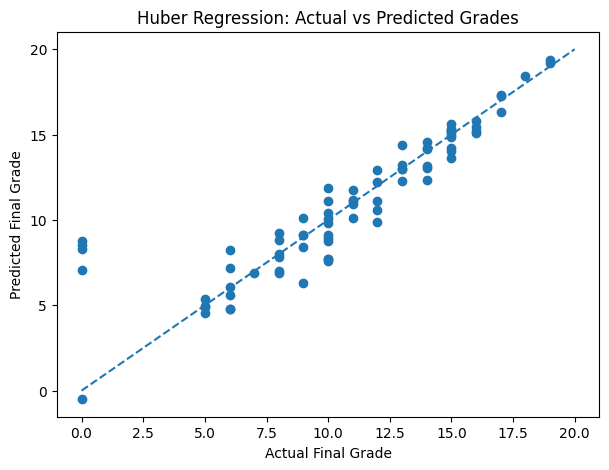

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test_reg,
    y_pred_huber
)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--"
)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Huber Regression: Actual vs Predicted Grades")

plt.show()

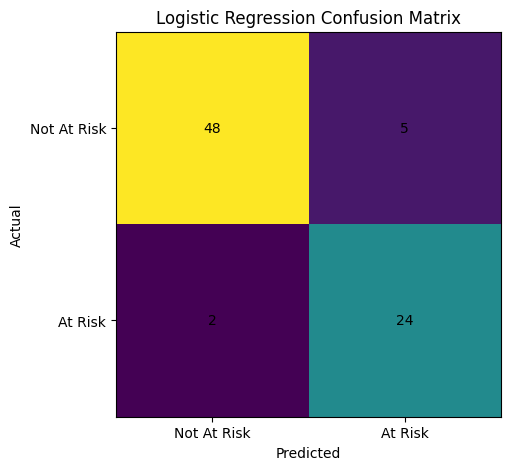

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(logistic_cm)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["Not At Risk", "At Risk"]
)

plt.yticks(
    [0, 1],
    ["Not At Risk", "At Risk"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            logistic_cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

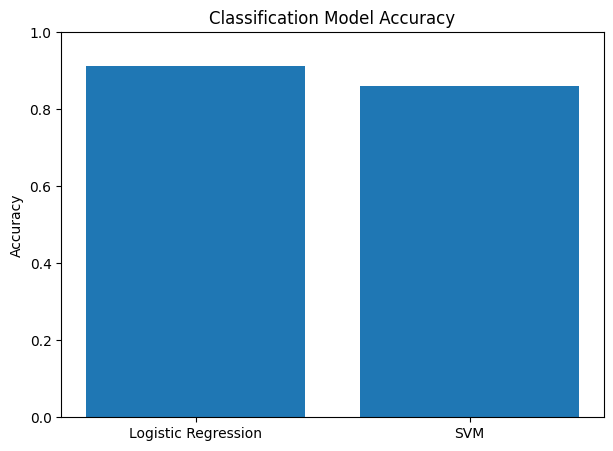

In [ ]:
models = ["Logistic Regression", "SVM"]

accuracy_values = [
    logistic_accuracy,
    svm_accuracy
]

plt.figure(figsize=(7, 5))

plt.bar(
    models,
    accuracy_values
)

plt.ylim(0, 1)

plt.ylabel("Accuracy")
plt.title("Classification Model Accuracy")

plt.show()

In [ ]:
print("======================================")
print("        FINAL MODEL PERFORMANCE")
print("======================================")

print("\nHuber Regression")
print("MAE :", round(huber_mae, 3))
print("RMSE:", round(huber_rmse, 3))
print("R²  :", round(huber_r2, 3))
print("CV Mean R²:", round(huber_cv_scores.mean(), 3))

print("\nLogistic Regression")
print("Accuracy :", round(logistic_accuracy, 3))
print("Precision:", round(logistic_precision, 3))
print("Recall   :", round(logistic_recall, 3))
print("F1 Score :", round(logistic_f1, 3))
print("CV Mean Accuracy:", round(logistic_cv_scores.mean(), 3))

        FINAL MODEL PERFORMANCE

Huber Regression
MAE : 1.105
RMSE: 2.073
R²  : 0.79
CV Mean R²: 0.812

Logistic Regression
Accuracy : 0.911
Precision: 0.828
Recall   : 0.923
F1 Score : 0.873
CV Mean Accuracy: 0.901


In [ ]:
def predict_student(
    age,
    sex,
    address,
    Medu,
    Fedu,
    traveltime,
    studytime,
    failures,
    famsup,
    higher,
    famrel,
    absences,
    G1,
    G2
):

    student = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "address": address,
        "Medu": Medu,
        "Fedu": Fedu,
        "traveltime": traveltime,
        "studytime": studytime,
        "failures": failures,
        "famsup": famsup,
        "higher": higher,
        "famrel": famrel,
        "absences": absences,
        "G1": G1,
        "G2": G2
    }])

    student_encoded = pd.get_dummies(
        student,
        drop_first=True
    )

    student_encoded = student_encoded.reindex(
        columns=X.columns,
        fill_value=0
    )

    predicted_grade = huber_model.predict(
        student_encoded
    )[0]

    predicted_risk = logistic_model.predict(
        student_encoded
    )[0]

    print("\n========================================")
    print("       STUDENT PERFORMANCE PREDICTION")
    print("========================================")

    print(
        "Predicted Final Grade:",
        round(predicted_grade, 2),
        "/ 20"
    )

    if predicted_risk == 1:
        print("Academic Risk: AT RISK")
    else:
        print("Academic Risk: NOT AT RISK")

    print("========================================")

In [ ]:
age = int(input("Enter student's age: "))

sex = input("Enter sex (M/F): ").upper()

address = input("Enter address type (U/R): ").upper()


print("\nMother's Education")
print("1. None")
print("2. Primary")
print("3. 5th-9th grade")
print("4. Secondary")
print("5. Higher education")

Medu = int(input("Choose 1-5: ")) - 1


print("\nFather's Education")
print("1. None")
print("2. Primary")
print("3. 5th-9th grade")
print("4. Secondary")
print("5. Higher education")

Fedu = int(input("Choose 1-5: ")) - 1


traveltime = int(
    input("\nTravel time (1-4): ")
)

studytime = int(
    input("Study time (1-4): ")
)

failures = int(
    input("Number of past failures (0-3): ")
)

famsup = input(
    "Family educational support (yes/no): "
).lower()

higher = input(
    "Wants higher education (yes/no): "
).lower()

famrel = int(
    input("Family relationship quality (1-5): ")
)

absences = int(
    input("Number of absences: ")
)

G1 = int(
    input("Enter G1 grade (0-20): ")
)

G2 = int(
    input("Enter G2 grade (0-20): ")
)


predict_student(
    age,
    sex,
    address,
    Medu,
    Fedu,
    traveltime,
    studytime,
    failures,
    famsup,
    higher,
    famrel,
    absences,
    G1,
    G2
)

KeyboardInterrupt: Interrupted by user

!pip install -q gradio

In [ ]:
import gradio as gr

def test(name):
    return "Hello " + name

demo = gr.Interface(
    fn=test,
    inputs=gr.Textbox(label="Enter your name"),
    outputs=gr.Textbox(label="Result")
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://841cea5d15d35bab62.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr

In [ ]:
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown("""
    # 🎓 Student Academic Performance Predictor
    ### Machine Learning Based Academic Performance & Risk Prediction
    """)

    gr.Markdown(
        "Enter the student's information below to predict their final grade "
        "and academic risk."
    )

    with gr.Row():

        with gr.Column():
            gr.Markdown("### 👤 Student Information")

            age = gr.Number(
                label="Age",
                value=17,
                minimum=15,
                maximum=30
            )

            sex = gr.Dropdown(
                ["Male", "Female"],
                label="Gender",
                value="Male"
            )

            address = gr.Dropdown(
                ["Urban", "Rural"],
                label="Area",
                value="Urban"
            )

            traveltime = gr.Dropdown(
                [
                    ("< 15 minutes", 1),
                    ("15–30 minutes", 2),
                    ("30–60 minutes", 3),
                    ("> 60 minutes", 4)
                ],
                label="Travel Time to Institution",
                value=1
            )

        with gr.Column():
            gr.Markdown("### 👨‍👩‍👦 Family Information")

            Medu = gr.Dropdown(
                [
                    ("None", 0),
                    ("Primary education", 1),
                    ("5th–9th grade", 2),
                    ("Secondary education", 3),
                    ("Higher education", 4)
                ],
                label="Mother's Education",
                value=3
            )

            Fedu = gr.Dropdown(
                [
                    ("None", 0),
                    ("Primary education", 1),
                    ("5th–9th grade", 2),
                    ("Secondary education", 3),
                    ("Higher education", 4)
                ],
                label="Father's Education",
                value=3
            )

            famsup = gr.Dropdown(
                ["Yes", "No"],
                label="Family Educational Support",
                value="Yes"
            )

            famrel = gr.Slider(
                minimum=1,
                maximum=5,
                step=1,
                value=4,
                label="Family Relationship Quality"
            )

    with gr.Row():

        with gr.Column():
            gr.Markdown("### 📚 Study Information")

            studytime = gr.Dropdown(
                [
                    ("< 2 hours", 1),
                    ("2–5 hours", 2),
                    ("5–10 hours", 3),
                    ("> 10 hours", 4)
                ],
                label="Weekly Study Time",
                value=2
            )

            failures = gr.Slider(
                minimum=0,
                maximum=3,
                step=1,
                value=0,
                label="Number of Past Class Failures"
            )

            higher = gr.Dropdown(
                ["Yes", "No"],
                label="Wants Higher Education",
                value="Yes"
            )

            absences = gr.Number(
                label="Number of Absences",
                value=2,
                minimum=0
            )

        with gr.Column():
            gr.Markdown("### 📊 Previous Academic Performance")

            G1 = gr.Number(
                label="First Period Grade (G1)",
                value=12,
                minimum=0,
                maximum=20
            )

            G2 = gr.Number(
                label="Second Period Grade (G2)",
                value=12,
                minimum=0,
                maximum=20
            )

    predict_button = gr.Button(
        "🔮 Predict Academic Performance",
        variant="primary"
    )

    gr.Markdown("### 🎯 Prediction Results")

    predicted_grade = gr.Number(
        label="Predicted Final Grade (G3)"
    )

    predicted_risk = gr.Textbox(
        label="Academic Risk"
    )

    predict_button.click(
        fn=predict_student,
        inputs=[
            age,
            sex,
            address,
            Medu,
            Fedu,
            traveltime,
            studytime,
            failures,
            famsup,
            higher,
            famrel,
            absences,
            G1,
            G2
        ],
        outputs=[
            predicted_grade,
            predicted_risk
        ]
    )

demo.launch(share=True)

/tmp/ipykernel_1778/3075598394.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c6ed3726ee240bdcb1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
demo.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c6ed3726ee240bdcb1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
def predict_student(
    age,
    sex,
    address,
    Medu,
    Fedu,
    traveltime,
    studytime,
    failures,
    famsup,
    higher,
    famrel,
    absences,
    G1,
    G2
):

    student = pd.DataFrame([{
        "age": age,
        "sex": "M" if sex == "Male" else "F",
        "address": "U" if address == "Urban" else "R",
        "Medu": Medu,
        "Fedu": Fedu,
        "traveltime": traveltime,
        "studytime": studytime,
        "failures": failures,
        "famsup": "yes" if famsup == "Yes" else "no",
        "higher": "yes" if higher == "Yes" else "no",
        "famrel": famrel,
        "absences": absences,
        "G1": G1,
        "G2": G2
    }])

    # Convert categorical values into the same format used during training
    student_encoded = pd.get_dummies(student, drop_first=True)

    # Make sure the columns exactly match the training data
    student_encoded = student_encoded.reindex(
        columns=X.columns,
        fill_value=0
    )

    # Predictions
    predicted_grade = huber_model.predict(student_encoded)[0]
    predicted_risk = logistic_model.predict(student_encoded)[0]

    # Return values to Gradio
    if predicted_risk == 1:
        risk_text = "⚠️ AT RISK"
    else:
        risk_text = "✅ NOT AT RISK"

    return round(predicted_grade, 2), risk_text

In [ ]:
demo.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c6ed3726ee240bdcb1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
demo.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c6ed3726ee240bdcb1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
css = """
/* Main background */
.gradio-container {
    max-width: 1200px !important;
    margin: auto !important;
}

/* Smooth page appearance */
.gradio-container {
    animation: pageFade 0.8s ease-out;
}

@keyframes pageFade {
    from {
        opacity: 0;
        transform: translateY(15px);
    }
    to {
        opacity: 1;
        transform: translateY(0);
    }
}

/* Hero section */
.hero {
    text-align: center;
    padding: 25px;
    border-radius: 18px;
    margin-bottom: 25px;
    background: linear-gradient(
        120deg,
        #4338ca,
        #6366f1,
        #7c3aed,
        #4338ca
    );
    background-size: 300% 300%;
    animation: gradientMove 8s ease infinite;
    box-shadow: 0 10px 30px rgba(99, 102, 241, 0.25);
}

@keyframes gradientMove {
    0% {
        background-position: 0% 50%;
    }
    50% {
        background-position: 100% 50%;
    }
    100% {
        background-position: 0% 50%;
    }
}

/* Section cards */
.section-card {
    border-radius: 16px !important;
    padding: 8px !important;
    transition: all 0.3s ease;
}

.section-card:hover {
    transform: translateY(-3px);
    box-shadow: 0 8px 25px rgba(99, 102, 241, 0.12);
}

/* Predict button */
.predict-btn {
    transition: all 0.25s ease !important;
    border-radius: 12px !important;
}

.predict-btn:hover {
    transform: translateY(-3px) scale(1.01);
    box-shadow: 0 8px 25px rgba(99, 102, 241, 0.35);
}

.predict-btn:active {
    transform: scale(0.98);
}

/* Result cards */
.result-card {
    animation: resultAppear 0.6s ease-out;
    transition: all 0.3s ease;
}

.result-card:hover {
    transform: translateY(-2px);
}

@keyframes resultAppear {
    from {
        opacity: 0;
        transform: translateY(12px);
    }
    to {
        opacity: 1;
        transform: translateY(0);
    }
}

/* Input hover effect */
.gradio-container input,
.gradio-container textarea,
.gradio-container button,
.gradio-container select {
    transition: all 0.2s ease !important;
}

/* Footer */
.footer {
    text-align: center;
    opacity: 0.65;
    margin-top: 25px;
    font-size: 13px;
}
"""


with gr.Blocks(
    theme=gr.themes.Soft(),
    css=css
) as demo:

    # =========================
    # HERO
    # =========================

    gr.HTML("""
    <div class="hero">
        <h1>🎓 Student Academic Performance Predictor</h1>
        <p>Machine Learning Based Academic Performance & Risk Prediction</p>
        <p>Enter student information to predict final academic performance.</p>
    </div>
    """)

    # =========================
    # STUDENT + FAMILY
    # =========================

    with gr.Row():

        with gr.Column(elem_classes="section-card"):

            gr.Markdown("### 👤 Student Information")

            age = gr.Number(
                label="Age",
                value=17,
                minimum=15,
                maximum=30
            )

            sex = gr.Dropdown(
                ["Male", "Female"],
                label="Gender",
                value="Male"
            )

            address = gr.Dropdown(
                ["Urban", "Rural"],
                label="Area",
                value="Urban"
            )

            traveltime = gr.Dropdown(
                [
                    ("< 15 minutes", 1),
                    ("15–30 minutes", 2),
                    ("30–60 minutes", 3),
                    ("> 60 minutes", 4)
                ],
                label="Travel Time to Institution",
                value=1
            )

        with gr.Column(elem_classes="section-card"):

            gr.Markdown("### 👨‍👩‍👦 Family Information")

            Medu = gr.Dropdown(
                [
                    ("None", 0),
                    ("Primary education", 1),
                    ("5th–9th grade", 2),
                    ("Secondary education", 3),
                    ("Higher education", 4)
                ],
                label="Mother's Education",
                value=3
            )

            Fedu = gr.Dropdown(
                [
                    ("None", 0),
                    ("Primary education", 1),
                    ("5th–9th grade", 2),
                    ("Secondary education", 3),
                    ("Higher education", 4)
                ],
                label="Father's Education",
                value=3
            )

            famsup = gr.Dropdown(
                ["Yes", "No"],
                label="Family Educational Support",
                value="Yes"
            )

            famrel = gr.Slider(
                minimum=1,
                maximum=5,
                step=1,
                value=4,
                label="Family Relationship Quality"
            )

    # =========================
    # STUDY + ACADEMIC
    # =========================

    with gr.Row():

        with gr.Column(elem_classes="section-card"):

            gr.Markdown("### 📚 Study Information")

            studytime = gr.Dropdown(
                [
                    ("< 2 hours", 1),
                    ("2–5 hours", 2),
                    ("5–10 hours", 3),
                    ("> 10 hours", 4)
                ],
                label="Weekly Study Time",
                value=2
            )

            failures = gr.Slider(
                minimum=0,
                maximum=3,
                step=1,
                value=0,
                label="Number of Past Class Failures"
            )

            higher = gr.Dropdown(
                ["Yes", "No"],
                label="Wants Higher Education",
                value="Yes"
            )

            absences = gr.Number(
                label="Number of Absences",
                value=2,
                minimum=0
            )

        with gr.Column(elem_classes="section-card"):

            gr.Markdown("### 📊 Previous Academic Performance")

            G1 = gr.Number(
                label="First Period Grade (G1)",
                value=12,
                minimum=0,
                maximum=20
            )

            G2 = gr.Number(
                label="Second Period Grade (G2)",
                value=12,
                minimum=0,
                maximum=20
            )

    # =========================
    # PREDICT BUTTON
    # =========================

    predict_button = gr.Button(
        "🔮 Predict Academic Performance",
        variant="primary",
        elem_classes="predict-btn"
    )

    # =========================
    # RESULTS
    # =========================

    gr.Markdown("### 🎯 Prediction Results")

    with gr.Row():

        predicted_grade = gr.Number(
            label="Predicted Final Grade (G3)",
            elem_classes="result-card"
        )

        predicted_risk = gr.Textbox(
            label="Academic Risk",
            elem_classes="result-card"
        )

    # =========================
    # MODEL INFORMATION
    # =========================

    gr.Markdown("""
    ### 🤖 Models Used

    **Huber Regression** → Final Grade Prediction
    **Logistic Regression** → Academic Risk Classification

    The predictions are based on the student's demographic,
    family, study and previous academic performance information.
    """)

    gr.HTML("""
    <div class="footer">
        Student Academic Performance Prediction System • Machine Learning Project
    </div>
    """)

    # =========================
    # PREDICTION FUNCTION
    # =========================

    predict_button.click(
        fn=predict_student,
        inputs=[
            age,
            sex,
            address,
            Medu,
            Fedu,
            traveltime,
            studytime,
            failures,
            famsup,
            higher,
            famrel,
            absences,
            G1,
            G2
        ],
        outputs=[
            predicted_grade,
            predicted_risk
        ]
    )

/tmp/ipykernel_1778/3297364830.py:120: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


In [ ]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a5c2a1e34ec3a3251a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
